part one

In [17]:
import matplotlib.pyplot as plt
import csv

with open("simpler_data_rwc.csv", mode="r", newline="", encoding="utf-8") as file:
    reader = csv.reader(file)
    header = next(reader)
    x = [int(i) for i in header[7:]]
    counter = 0
    for row in reader:
        if counter % 67 == 0:
            y = [float(i) for i in row[7:]]
            plt.plot(x,y)
            plt.savefig("pt1_plots/" + row[0] + "_plot.png")
            plt.clf()
        counter+=1
    print(len(y))

210


<Figure size 640x480 with 0 Axes>

part two

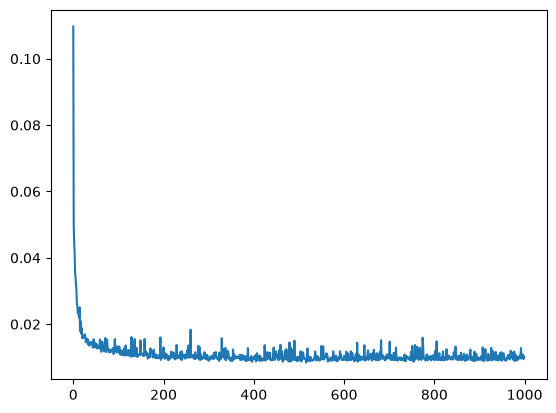

In [25]:
import torch
import numpy as np
from torch.utils.data import TensorDataset, DataLoader
from IPython.display import clear_output

model = torch.nn.Sequential(
    torch.nn.Linear(210,128),
    torch.nn.ReLU(),
    torch.nn.Linear(128,3),
    torch.nn.ReLU()
)

training_input = []
training_output = []

test_input = []
test_output = []

with open("simpler_data_rwc.csv", mode="r", newline="", encoding="utf-8") as file:
    reader = csv.reader(file)
    header = next(reader)
    counter = 0
    for row in reader:
        input = [float(i) for i in row[7:]]
        output = [float(i) for i in row[1:4]]
        if counter % 10 == 0:
            test_input.append(input)
            test_output.append(output)
        else:
            training_input.append(input)
            training_output.append(output)
        counter+=1

training_dataset = TensorDataset(torch.tensor(training_input, dtype=torch.float32), torch.tensor(training_output, dtype=torch.float32))
test_dataset = TensorDataset(torch.tensor(test_input, dtype=torch.float32), torch.tensor(test_output, dtype=torch.float32))

training_loader = DataLoader(training_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

loss_func = torch.nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

model.train()

losses = []
epochs = []
for epoch in range(1000):
    model.train()
    for i, data in enumerate(training_loader):
        input, expected = data
        optimizer.zero_grad()
        predicted = model(input)
        loss = loss_func(predicted, expected)
        loss.backward()
        optimizer.step()

    model.eval()
    total_loss = 0
    total_tests = 0
    for i, data in enumerate(test_loader):
        input, expected = data
        predicted = model(input)
        loss = loss_func(predicted, expected)
        total_loss += loss.item()
        total_tests += 1
    
    print("epoch " + str(epoch) + " loss: " + str(total_loss / total_tests))
    losses.append(total_loss/total_tests)
    epochs.append(epoch)
    clear_output(wait=True)
    plt.plot(epochs, losses)
    plt.show()

